Specificity: Computes the Kalman filter on IV. It also does training on quotes and testing on trades. Results+evaluations plotted. 

In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)


import arbitrage
import black_scholes
import ekf
import events
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.plots as plots
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [3]:
from datetime import date

from quantdata.biz_calendar import add_business_days

expiry_date = date(2024, 1, 5)
trade_date = add_business_days(expiry_date, -20)

In [4]:
# trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

In [ ]:
# Single call — processes all calls and puts in one batched IV computation.
# is_call column in the output distinguishes the two types.
df_quote_result, df_trade_result = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)

O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2023-12-06 15:05:34.267399-05:00))
O:SPY240105C00479000: dropping 2 bad quotes (crossed×2 (first=2023-12-06 13:17:33.558137-05:00))
O:SPY240105C00480000: dropping 2 bad quotes (crossed×2 (first=2023-12-06 15:59:45.161641-05:00))
O:SPY240105C00483000: dropping 1 bad quotes (crossed×1 (first=2023-12-06 10:30:44.786510-05:00))
Skipping O:SPY240105P00462000: no matched trades
Skipping O:SPY240105P00462500: no matched trades
Skipping O:SPY240105P00463000: no matched trades
Skipping O:SPY240105P00464000: no matched trades
Skipping O:SPY240105P00466000: no matched trades
Skipping O:SPY240105P00469000: no matched trades
Skipping O:SPY240105P00470000: no matched trades
Skipping O:SPY240105P00471000: no matched trades
Skipping O:SPY240105P00474000: no matched trades
Skipping O:SPY240105P00477000: no matched trades
Expiry 2024-01-05: implied forward from 7 overlapping strike(s), 149198/149198 rows with non-null discount_factor


In [ ]:
df_spy

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 04:00:00.023728896 EST,472.04,4.0,73728
2024-01-03 04:00:00.033502208 EST,472.43,16.0,73728
2024-01-03 04:00:00.035570944 EST,472.36,1.0,73728
2024-01-03 04:00:00.035577088 EST,472.31,4.0,73728
2024-01-03 04:00:00.370607616 EST,472.16,2.0,73728
…,…,…,…
2024-01-03 19:59:57.242399488 EST,469.35,100.0,8192
2024-01-03 19:59:57.242399488 EST,469.35,400.0,8192
2024-01-03 19:59:58.998797568 EST,469.355,1.0,73728


In [ ]:
df_quote_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_iv,bid_price,ask_price,forward,discount_factor,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.003357440 EST,0.31989,0.312129,0.326719,0.31989,0.02,0.03,470.43,1.0,0.025173,442.0,false
2024-01-03 09:30:00.006736128 EST,0.140982,0.138439,0.143359,0.140982,0.04,0.05,470.43,1.0,0.045034,481.0,true
2024-01-03 09:30:00.006781440 EST,0.13695,0.134075,0.139497,0.13695,0.09,0.11,470.43,1.0,0.100363,479.0,true
2024-01-03 09:30:00.007484160 EST,0.143359,0.132705,0.15164,0.141236,0.03,0.07,470.43,1.0,0.045551,481.0,true
2024-01-03 09:30:00.008294144 EST,0.127732,0.126371,0.129092,0.127732,2.17,2.21,470.43,1.0,2.189967,471.0,false
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,0.145804,0.145401,0.146126,0.145803,1.88,1.89,468.74,1.0,1.88553,469.0,true
2024-01-03 16:14:59.884593152 EST,0.091882,0.07433,0.104474,0.093966,5.28,5.38,468.74,1.0,5.334368,474.0,false
2024-01-03 16:14:59.884598272 EST,0.110311,0.108205,0.114425,0.110651,3.66,3.72,468.74,1.0,3.68344,472.0,false


In [ ]:
df_quote_result["discount_factor"].describe()

statistic,value
str,f64
"""count""",3.173691e6
"""null_count""",0.0
"""mean""",1.0
"""std""",0.0
"""min""",1.0
"""25%""",1.0
"""50%""",1.0
"""75%""",1.0
"""max""",1.0


(array([      0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0., 3173691.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.,       0.,       0.,       0.,       0.,
              0.,       0.]),
 array([0.5 , 0.52, 0.54, 0.56, 0.58, 0.6 , 0.62, 0.64, 0.66, 0.68, 0.7 ,
        0.72, 0.74, 0.76, 0.78, 0.8 , 0.82, 0.84, 0.86, 0.88, 0.9 , 0.92,
        0.94, 0.96, 0.98, 1.  , 1.02, 1.04, 1.06, 1.08, 1.1 , 1.12, 1.14,
        1.16, 1.18, 1.2 , 1.22, 1.24, 1.26, 1.28, 1.3 , 1.32, 1.34, 1.36,
        1.38, 1.4 , 1.42, 1.44, 1.46, 1.48, 1.5 ]),
 <BarContainer object of 50 artists>)

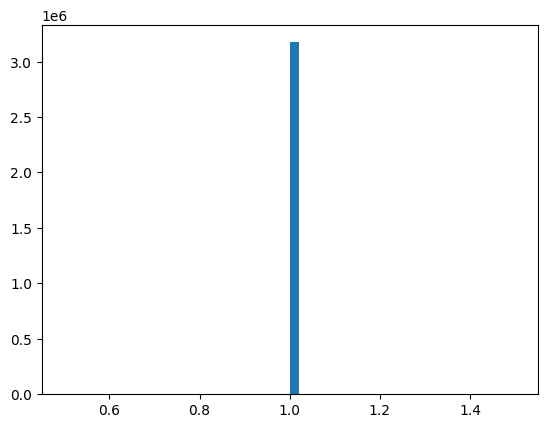

In [ ]:
plt.hist(df_quote_result["discount_factor"], bins=50)

In [ ]:
df_quote_result["discount_factor"][-100000]

1.0

In [ ]:
df_quote_result["forward"].is_null().sum()

0

In [ ]:
df_quote_result["discount_factor"].is_null().sum()

0

In [ ]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.137318,-0.006573,0.103182,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.059 EST,0.153329,0.01,0.1651,0.0,0.05,null,null,NaN,483.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150646,0.003677,0.227992,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.128923,0.128139,0.128923,1.03,1.04,0.12846,0.000463,1.034098,467.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false


In [ ]:
df_trade_result = df_trade_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
print(f"{df_trade_result.shape[0]:,} rows with no nulls / NaNs out of {df_trade_result.shape[0]:,}")

74,831 rows with no nulls / NaNs out of 74,831


In [ ]:
df_trade_result.select(pl.col("trade_residual") ** 2).mean() * 100000

trade_residual
f64
1.571381


## Quptes smile

In [ ]:
import personal.shared_functions.utils as _u

df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"IV smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [ ]:
row

ts_ns,bid_iv_270_C,ask_iv_270_C,kalman_iv_270_C,bid_iv_375_C,ask_iv_375_C,kalman_iv_375_C,bid_iv_376_C,ask_iv_376_C,kalman_iv_376_C,bid_iv_378_C,ask_iv_378_C,kalman_iv_378_C,bid_iv_379_C,ask_iv_379_C,kalman_iv_379_C,bid_iv_386_C,ask_iv_386_C,kalman_iv_386_C,bid_iv_387_C,ask_iv_387_C,kalman_iv_387_C,bid_iv_397_C,ask_iv_397_C,kalman_iv_397_C,bid_iv_400_C,ask_iv_400_C,kalman_iv_400_C,bid_iv_406_C,ask_iv_406_C,kalman_iv_406_C,bid_iv_410_C,ask_iv_410_C,kalman_iv_410_C,bid_iv_421_C,ask_iv_421_C,kalman_iv_421_C,…,kalman_iv_480_P,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_P,ask_iv_481_P,kalman_iv_481_P,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_P,ask_iv_482_P,kalman_iv_482_P,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_P,ask_iv_483_P,kalman_iv_483_P,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,bid_iv_485_P,ask_iv_485_P,kalman_iv_485_P,bid_iv_490_P,ask_iv_490_P,kalman_iv_490_P,bid_iv_493_P,ask_iv_493_P,kalman_iv_493_P,bid_iv_500_P,ask_iv_500_P,kalman_iv_500_P
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 14:04:53.013474304 EST,0.01,3.714766,2.718145,0.01,1.694864,1.375521,0.01,1.682541,1.366429,0.01,1.63896,1.340135,0.01,1.625573,1.329976,0.01,1.494285,1.228198,0.01,1.502504,1.223902,0.01,1.337222,1.095877,0.01,1.287883,1.031229,0.01,1.191274,0.972656,0.01,1.127417,0.906429,0.01,0.937449,0.760465,…,0.046097,0.144515,0.148946,0.14636,0.01,0.214877,0.047364,0.148901,0.155197,0.151751,0.01,0.242006,0.056591,0.15118,0.159875,0.154571,0.01,0.254611,0.071656,0.161197,0.1704,0.162625,0.15233,0.161041,0.155063,0.01,0.279131,0.076664,0.01,0.396709,0.134363,0.01,0.441135,0.138707,0.01,0.532108,0.164384


In [ ]:
spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    has_C = f"kalman_iv_{K_int}_C" in row.columns
    has_P = f"kalman_iv_{K_int}_P" in row.columns

    bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
    ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
    bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
    ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

    if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
        i_bid = max(bid_C, bid_P)
        i_ask = min(ask_C, ask_P)
        if i_bid <= i_ask:
            # spreads overlap → use intersection
            otm_bid.append(i_bid)
            otm_ask.append(i_ask)
            otm_mid.append((i_bid + i_ask) / 2)
        else:
            # no overlap → use OTM leg
            if k > spy_mid:
                otm_bid.append(bid_C)
                otm_ask.append(ask_C)
                otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
            else:
                otm_bid.append(bid_P)
                otm_ask.append(ask_P)
                otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    elif has_C and None not in (bid_C, ask_C):
        otm_bid.append(bid_C)
        otm_ask.append(ask_C)
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
    elif has_P and None not in (bid_P, ask_P):
        otm_bid.append(bid_P)
        otm_ask.append(ask_P)
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    else:
        otm_bid.append(None)
        otm_ask.append(None)
        otm_mid.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

# Check arbitrage some rows

In [ ]:
has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

for i in range(0, df_filtered.shape[0], 100):
    row = df_filtered[i]
    ts = row["ts_ns"][0]
    tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
    spy_mid = df_spy.filter(pl.col("ts_ns") <= ts)["price"][-1]

    valid_strikes, valid_ivs = [], []
    for k in otm_strikes:
        K_int = int(k)
        has_C = k in has_C_set
        has_P = k in has_P_set

        if has_C and has_P:
            bid_C, ask_C = row[f"bid_iv_{K_int}_C"][0], row[f"ask_iv_{K_int}_C"][0]
            bid_P, ask_P = row[f"bid_iv_{K_int}_P"][0], row[f"ask_iv_{K_int}_P"][0]
            i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
            iv = (
                (i_bid + i_ask) / 2
                if i_bid <= i_ask
                else (
                    row[f"kalman_iv_{K_int}_C"][0]
                    if k > spy_mid
                    else row[f"kalman_iv_{K_int}_P"][0]
                )
            )
        elif has_C:
            iv = row[f"kalman_iv_{K_int}_C"][0]
        elif has_P:
            iv = row[f"kalman_iv_{K_int}_P"][0]
        else:
            continue

        valid_strikes.append(k)
        valid_ivs.append(iv)

    if not arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
        "is_arbitrage_free"
    ]:
        print(f"Arbitrage detected at index {i} (timestamp {ts})")

Arbitrage detected at index 1071800 (timestamp 2024-01-03 14:02:34.839385-05:00)
Arbitrage detected at index 2139500 (timestamp 2024-01-03 15:55:20.577597-05:00)
Arbitrage detected at index 2144900 (timestamp 2024-01-03 15:55:44.663142-05:00)
Arbitrage detected at index 2145000 (timestamp 2024-01-03 15:55:44.777410-05:00)
Arbitrage detected at index 2145100 (timestamp 2024-01-03 15:55:45.140055-05:00)
Arbitrage detected at index 2145200 (timestamp 2024-01-03 15:55:45.712193-05:00)
Arbitrage detected at index 2145300 (timestamp 2024-01-03 15:55:45.892258-05:00)
Arbitrage detected at index 2145400 (timestamp 2024-01-03 15:55:46.117172-05:00)
Arbitrage detected at index 2146000 (timestamp 2024-01-03 15:55:48.943219-05:00)
Arbitrage detected at index 2146100 (timestamp 2024-01-03 15:55:49.188067-05:00)
Arbitrage detected at index 2146200 (timestamp 2024-01-03 15:55:49.609150-05:00)
Arbitrage detected at index 2146300 (timestamp 2024-01-03 15:55:49.799996-05:00)
Arbitrage detected at index 

Using parallelization

In [ ]:
# from joblib import Parallel, delayed
# from concurrent.futures import ThreadPoolExecutor

# # Single join_asof instead of a per-row filter on df_spy
# sample_df = df_filtered[::10]
# spy_mids = (
#     sample_df.select("ts_ns")
#     .join_asof(df_spy.sort("ts_ns").select("ts_ns", "price"), on="ts_ns", strategy="backward")[
#         "price"
#     ]
#     .to_list()
# )

# has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
# has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

# # Convert to plain Python once — avoids polars row access inside threads
# rows = sample_df.to_dicts()
# timestamps = sample_df["ts_ns"].to_list()


# def check_snapshot(i, row, ts, spy_mid, expiry, otm_strikes, has_C_set, has_P_set):
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C, has_P = k in has_C_set, k in has_P_set
#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"]
#         else:
#             continue
#         valid_strikes.append(k)
#         valid_ivs.append(iv)
#     is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]
#     return i, ts, is_free


# results = Parallel(n_jobs=-1, backend="loky")(
#     delayed(check_snapshot)(
#         i * 100, rows[i], timestamps[i], spy_mids[i], expiry, otm_strikes, has_C_set, has_P_set
#     )
#     for i in range(len(rows))
# )

# for idx, ts, is_free in results:
#     if not is_free:
#         print(f"Arbitrage detected at index {idx} (timestamp {ts})")


In [ ]:
# def check_snapshot(args):
#     i, row, ts, spy_mid = args
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C, has_P = k in has_C_set, k in has_P_set
#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"]
#         else:
#             continue
#         valid_strikes.append(k)
#         valid_ivs.append(iv)
#     is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]
#     return i, ts, is_free


# tasks = [(i * 100, rows[i], timestamps[i], spy_mids[i]) for i in range(len(rows))]

# with ThreadPoolExecutor() as executor:
#     for idx, ts, is_free in executor.map(check_snapshot, tasks):
#         if not is_free:
#             print(f"Arbitrage detected at index {idx} (timestamp {ts})")


In [ ]:
# for i in range(1, df_filtered.shape[0]):
#     row = df_filtered[i]
#     tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
#     mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
#     if not arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (calls) at index {i} (timestamp {row['ts_ns'][0]})")
#     mid_ivs_P = [row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P]
#     if not arbitrage.check_butterfly(k=strikes_P, iv=mid_ivs_P, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (puts) at index {i} (timestamp {row['ts_ns'][0]})")

In [ ]:
# with dropping quotes and min_trades = 100

# Arbitrage detected at index 32975500 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected at index 32975600 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected at index 32975700 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected at index 32975800 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected at index 32975900 (timestamp 2024-01-03 10:13:05.893470-05:00)

# Arbitrage detected (calls) at index 329755 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected (calls) at index 329756 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected (calls) at index 329757 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected (calls) at index 329758 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected (calls) at index 329759 (timestamp 2024-01-03 10:13:05.893470-05:00)
# Arbitrage detected (calls) at index 1503399 (timestamp 2024-01-03 14:20:23.701259-05:00)
# Arbitrage detected (calls) at index 1738694 (timestamp 2024-01-03 14:49:31.390834-05:00)

example plot

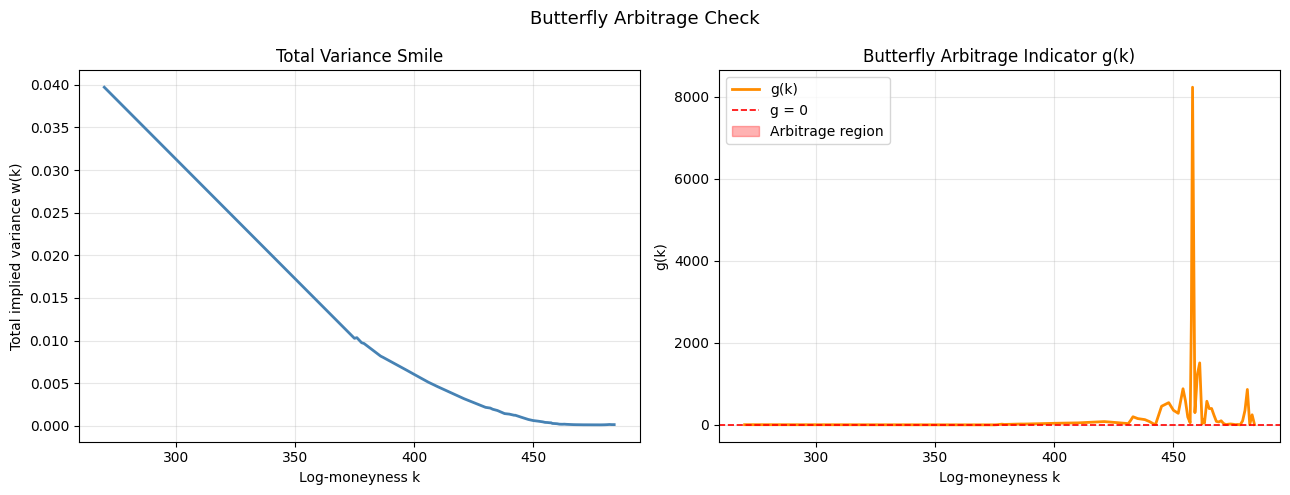

{'is_arbitrage_free': True,
 'min_g': 0.1264536064415257,
 'violations': array([], dtype=float64),
 'g': array([3.81702134e+00, 1.26453606e-01, 3.43098680e+00, 1.66602185e+01,
        9.45991176e+00, 2.04485830e+01, 1.93699029e+01, 3.28423260e+01,
        3.77382807e+01, 4.42116790e+01, 4.81839367e+01, 7.94662973e+01,
        3.58864300e+01, 2.83020504e+01, 1.06561325e+02, 1.97345235e+02,
        1.52735837e+02, 1.27020581e+02, 7.72229009e+01, 1.11486479e+01,
        1.42846458e+01, 4.53266960e+02, 5.41186303e+02, 3.54283979e+02,
        2.81554338e+02, 8.80183718e+02, 5.93115690e+02, 1.89954559e+02,
        5.13633695e+01, 2.56705064e+03, 8.23552908e+03, 2.96890141e+02,
        1.21936588e+03, 1.51118148e+03, 2.35442069e+01, 1.36038763e+02,
        4.29913810e+01, 5.75722034e+02, 3.96165153e+02, 3.98736757e+02,
        2.34057932e+02, 8.34910697e+01, 7.01261382e+01, 9.91251707e+01,
        3.31357967e+01, 6.11233267e+00, 1.54855584e+01, 2.09623184e+01,
        1.43390067e+01, 4.451698

In [ ]:
row = df_filtered[2144000]
tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=True)

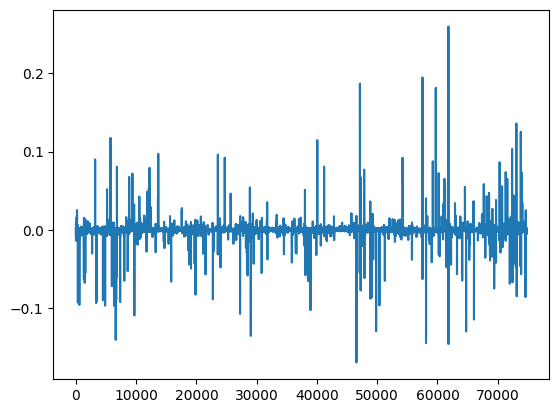

In [ ]:
plt.plot(df_trade_result["trade_residual"])

In [ ]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.137318,-0.006573,0.103182,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150646,0.003677,0.227992,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
2024-01-03 09:30:00.111 EST,0.145379,0.140452,0.150292,1.4,1.54,0.145914,-0.000535,1.477615,472.0,true
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.128923,0.128139,0.128923,1.03,1.04,0.12846,0.000463,1.034098,467.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false


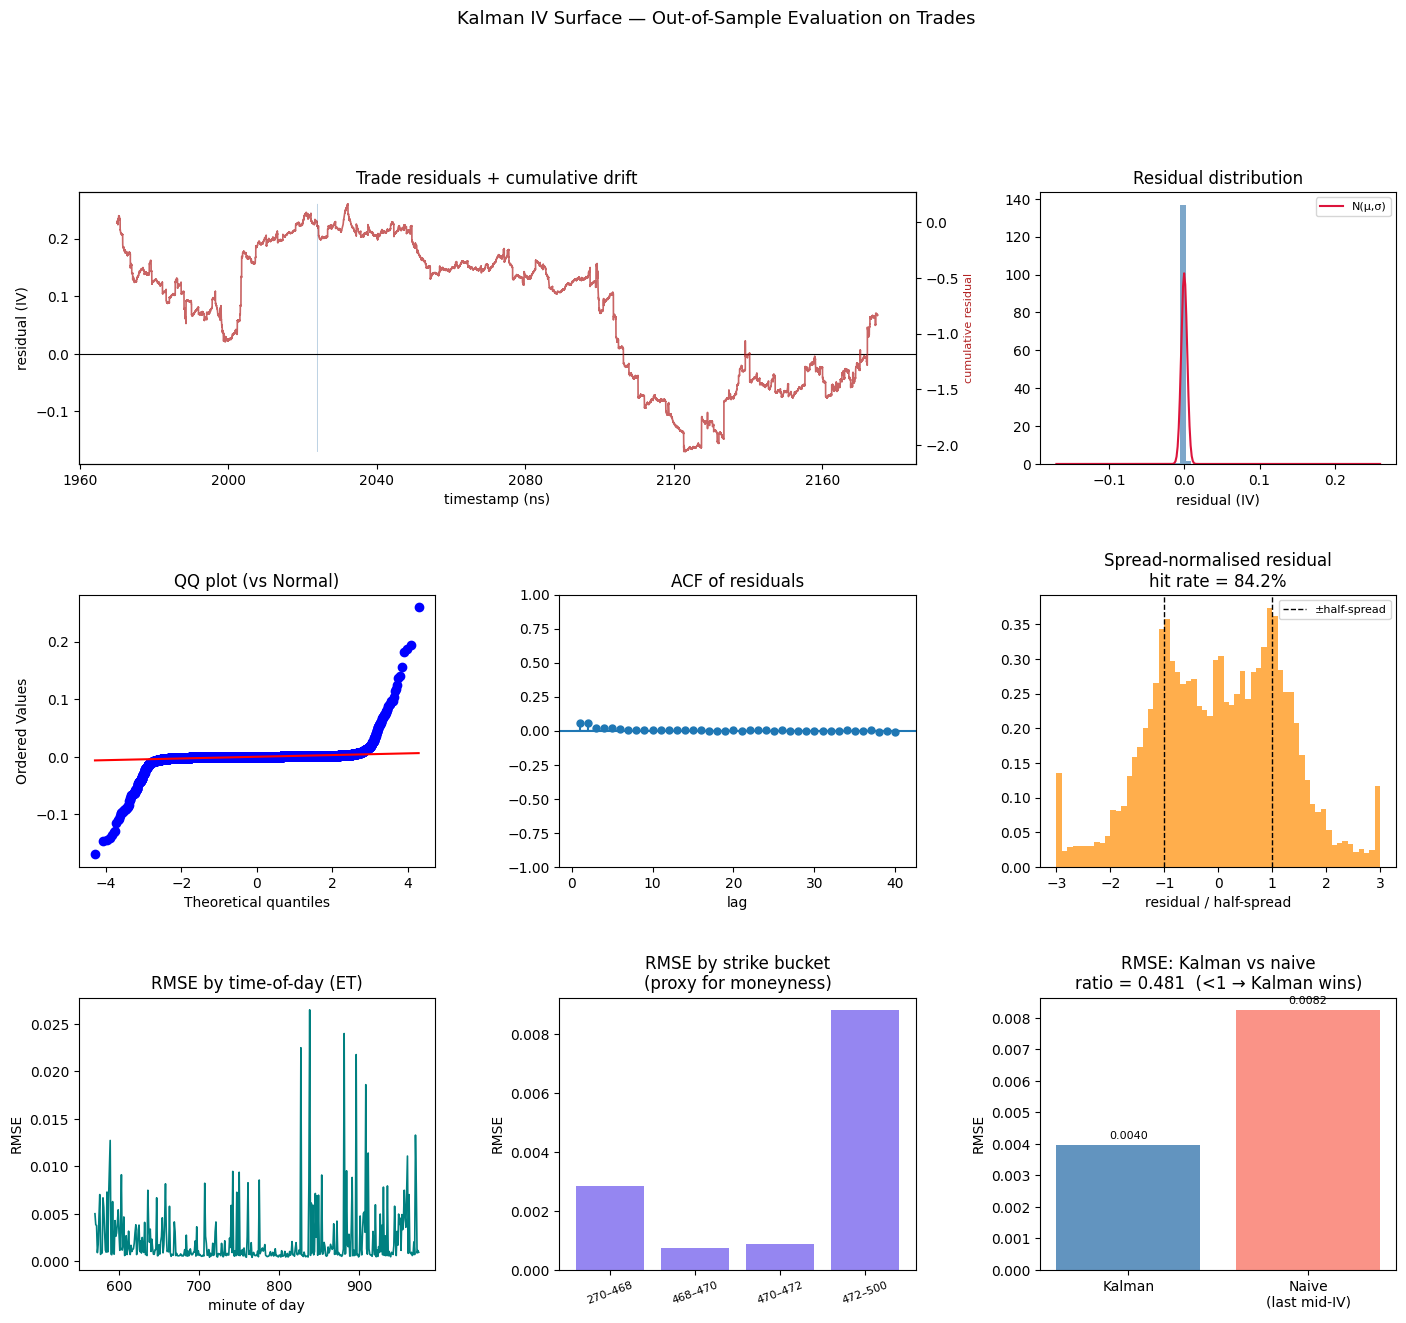

RMSE                 0.00396
MAE                  0.00080
Bias                 -0.00001
Hit rate             84.2%
Naive RMSE           0.00824
RMSE ratio           0.481  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
       lb_stat      lb_pvalue
10  594.603039  2.523659e-121
20  600.645410  2.104771e-114


In [ ]:
metrics = evaluate_kalman_iv(df_quote_result, df_trade_result)

In [ ]:
df_price_surface_wide = utils.synchronize_price_surface(
    df_quote_result.rename({"kalman_price": "observed_price"})
)

In [ ]:
df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
df_price_surface_long = df_quote_result.rename({"kalman_price": "observed_price"})

strikes_all = sorted(df_price_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_price_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_price_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered_price.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered_price["ts_ns"][row_idx]
row = df_price_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"observed_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"observed_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"price smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [ ]:
row

ts_ns,bid_price_270_C,ask_price_270_C,observed_price_270_C,bid_price_375_C,ask_price_375_C,observed_price_375_C,bid_price_376_C,ask_price_376_C,observed_price_376_C,bid_price_378_C,ask_price_378_C,observed_price_378_C,bid_price_379_C,ask_price_379_C,observed_price_379_C,bid_price_386_C,ask_price_386_C,observed_price_386_C,bid_price_387_C,ask_price_387_C,observed_price_387_C,bid_price_397_C,ask_price_397_C,observed_price_397_C,bid_price_400_C,ask_price_400_C,observed_price_400_C,bid_price_406_C,ask_price_406_C,observed_price_406_C,bid_price_410_C,ask_price_410_C,observed_price_410_C,bid_price_421_C,ask_price_421_C,observed_price_421_C,…,observed_price_480_P,bid_price_480_C,ask_price_480_C,observed_price_480_C,bid_price_481_P,ask_price_481_P,observed_price_481_P,bid_price_481_C,ask_price_481_C,observed_price_481_C,bid_price_482_P,ask_price_482_P,observed_price_482_P,bid_price_482_C,ask_price_482_C,observed_price_482_C,bid_price_483_P,ask_price_483_P,observed_price_483_P,bid_price_483_C,ask_price_483_C,observed_price_483_C,bid_price_484_C,ask_price_484_C,observed_price_484_C,bid_price_485_P,ask_price_485_P,observed_price_485_P,bid_price_490_P,ask_price_490_P,observed_price_490_P,bid_price_493_P,ask_price_493_P,observed_price_493_P,bid_price_500_P,ask_price_500_P,observed_price_500_P
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 14:04:53.013474304 EST,199.01,200.54,199.717433,94.3,95.38,94.763972,93.29,94.46,93.83969,91.3,92.36,91.768567,90.28,91.48,90.887227,83.31,84.34,83.785431,82.31,83.46,82.84844,72.33,73.42,72.829804,69.32,70.4,69.773358,63.31,64.51,63.924,59.34,60.41,59.796921,48.3,49.47,48.91821,…,10.4703,0.05,0.06,0.054039,10.87,11.66,11.425,0.03,0.04,0.034465,11.85,12.7,12.4,0.02,0.03,0.023685,12.86,13.7,13.41,0.02,0.03,0.021435,0.02,0.03,0.022952,14.89,15.73,15.46,19.83,20.94,20.440014,22.86,23.95,23.440002,29.86,30.95,30.46


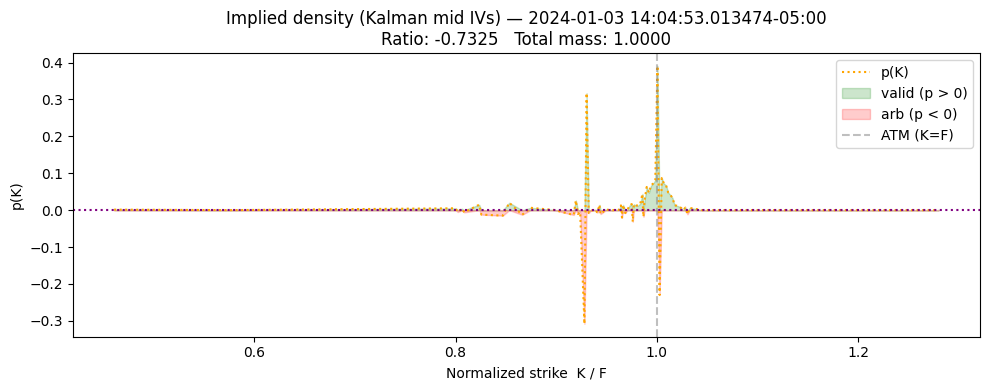

-0.7324669589641877 1.0


In [ ]:
# ── Implied probability density from Kalman IVs (Breeden-Litzenberger) ──────
# Depends on: snapshot_ts, expiry, spy_mid, otm_strikes, otm_mid
import scipy.stats as stats

row = df_filtered[21400]


def _bs_call(F, K, T, sigma):
    """Black-Scholes call price with r=0 (forward = spot)."""
    if sigma <= 0 or T <= 0:
        return float(max(F - K, 0.0))
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return float(F * stats.norm.cdf(d1) - K * stats.norm.cdf(d2))


F = spy_mid  # forward ≈ spot (r=0)
tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

# Filter strikes with a valid Kalman mid IV
valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
strikes = np.array([v[0] for v in valid])
ivs = np.array([v[1] for v in valid])

# Normalize to pure space: kappa = K/F, C_pure = C_BS / F
pure_strikes = strikes / F
pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

# Extend strike grid with boundary conditions
strikesx = np.zeros(len(pure_strikes) + 2)
strikesx[1:-1] = pure_strikes
strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

midx = np.zeros_like(strikesx)
midx[1:-1] = pure_mids
midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
midx[-1] = 0.0  # deep OTM call → 0

# Breeden-Litzenberger: d²C/dK² = risk-neutral density
dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
p = np.diff(dCdK, append=0.0)

ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
total = np.sum(p)  # should be ≈ 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_title(
    f"Implied density (Kalman mid IVs) — {snapshot_ts}\nRatio: {ratio:.4f}   Total mass: {total:.4f}"
)
ax.set_xlabel("Normalized strike  K / F")
ax.set_ylabel("p(K)")
ax.plot(strikesx, p, ":", color="orange", label="p(K)")
ax.fill_between(strikesx, 0, np.clip(p, 0, None), color="green", alpha=0.2, label="valid (p > 0)")
ax.fill_between(strikesx, np.clip(p, None, 0), 0, color="red", alpha=0.2, label="arb (p < 0)")
ax.axhline(0, color="purple", linestyle=":")
ax.axvline(1.0, color="gray", linestyle="--", alpha=0.5, label="ATM (K=F)")
ax.legend()
plt.tight_layout()
plt.show()

print(ratio, total)

In [ ]:
df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

In [ ]:
def extract_otm_details(row_idx, df_filtered, strikes_C, strikes_P):
    snapshot_ts = df_filtered["ts_ns"][row_idx]
    row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
    spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

    otm_strikes = sorted(set(strikes_C) | set(strikes_P))
    otm_mid, otm_bid, otm_ask = [], [], []

    for k in otm_strikes:
        K_int = int(k)
        has_C = f"kalman_iv_{K_int}_C" in row.columns
        has_P = f"kalman_iv_{K_int}_P" in row.columns

        bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
        ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
        bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
        ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

        if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
            i_bid = max(bid_C, bid_P)
            i_ask = min(ask_C, ask_P)
            if i_bid <= i_ask:
                # spreads overlap → use intersection
                otm_bid.append(i_bid)
                otm_ask.append(i_ask)
                otm_mid.append((i_bid + i_ask) / 2)
            else:
                # no overlap → use OTM leg
                if k > spy_mid:
                    otm_bid.append(bid_C)
                    otm_ask.append(ask_C)
                    otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
                else:
                    otm_bid.append(bid_P)
                    otm_ask.append(ask_P)
                    otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
        elif has_C and None not in (bid_C, ask_C):
            otm_bid.append(bid_C)
            otm_ask.append(ask_C)
            otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
        elif has_P and None not in (bid_P, ask_P):
            otm_bid.append(bid_P)
            otm_ask.append(ask_P)
            otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
        else:
            otm_bid.append(None)
            otm_ask.append(None)
            otm_mid.append(None)
    return otm_strikes, otm_mid, otm_bid, otm_ask

In [ ]:
def is_arbitrage_row_idx(row_idx, df_filtered, expiry):
    row = df_filtered[row_idx]
    ts = row["ts_ns"][0]
    tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
    otm_s, otm_m, _, _ = extract_otm_details(row_idx, df_filtered, strikes_C, strikes_P)
    valid = [(k, iv) for k, iv in zip(otm_s, otm_m) if iv is not None]
    if not valid:
        return {"is_arbitrage_free": True}
    ks, ivs = zip(*valid)
    return arbitrage.check_butterfly(k=list(ks), iv=list(ivs), T=tte, plot=False)

In [ ]:
def compute_negative_mass(row_idx, df_filtered, df_spy, expiry, otm_strikes, otm_mid):
    snapshot_ts = df_filtered["ts_ns"][row_idx]
    # F = spy_mid because forward ≈ spot (r=0)
    F = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

    tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

    # Filter strikes with a valid Kalman mid IV
    valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
    strikes = np.array([v[0] for v in valid])
    ivs = np.array([v[1] for v in valid])

    # Normalize to pure space: kappa = K/F, C_pure = C_BS / F
    pure_strikes = strikes / F
    pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

    # Extend strike grid with boundary conditions
    strikesx = np.zeros(len(pure_strikes) + 2)
    strikesx[1:-1] = pure_strikes
    strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
    strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

    midx = np.zeros_like(strikesx)
    midx[1:-1] = pure_mids
    midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
    midx[-1] = 0.0  # deep OTM call → 0

    # Breeden-Litzenberger: d²C/dK² = risk-neutral density
    dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
    p = np.diff(dCdK, append=0.0)

    ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
    total = np.sum(p)  # should be ≈ 1
    result = {
        "is_arbitrage_free": ratio >= 0.0,
        "negative_mass_ratio": ratio,
        "total_mass": total,
        "density": (strikesx, p),
    }
    return result

In [ ]:
import numpy as np

df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

# ── 1. Deduplicate strikes by int representation (column names use int(k)) ────
seen_C, seen_P = set(), set()
strikes_C_dedup, strikes_P_dedup = [], []
for k in strikes_C:
    if int(k) not in seen_C:
        seen_C.add(int(k))
        strikes_C_dedup.append(k)
for k in strikes_P:
    if int(k) not in seen_P:
        seen_P.add(int(k))
        strikes_P_dedup.append(k)

call_cols = [f"observed_price_{int(k)}_C" for k in strikes_C_dedup]
put_cols = [f"observed_price_{int(k)}_P" for k in strikes_P_dedup]

call_prices = df_filtered_price.select(call_cols).to_numpy()  # (n_rows, n_C)
put_prices = df_filtered_price.select(put_cols).to_numpy()  # (n_rows, n_P)


# ── 2. Vectorized Breeden-Litzenberger negative-mass over ALL rows at once ────
def compute_negative_mass(prices_2d: np.ndarray, strikes: list) -> np.ndarray:
    n_rows, _ = prices_2d.shape
    K = np.asarray(strikes, dtype=float)

    ext_K = np.concatenate([[K[0] * 0.8], K, [K[-1] * 1.2]])

    left_bd = 1.0 - ext_K[0]
    ext_prices = np.concatenate(
        [np.full((n_rows, 1), left_bd), prices_2d, np.zeros((n_rows, 1))],
        axis=1,
    )

    d_prices = np.diff(np.concatenate([np.ones((n_rows, 1)), ext_prices], axis=1), axis=1)
    d_K = np.diff(np.concatenate([[0.0], ext_K]))
    dCdK = d_prices / d_K[np.newaxis, :]

    p = np.diff(np.concatenate([dCdK, np.zeros((n_rows, 1))], axis=1), axis=1)

    return np.sum(np.minimum(p, 0.0), axis=1)


# ── 3. Run both legs ──────────────────────────────────────────────────────────
neg_mass_C = compute_negative_mass(call_prices, strikes_C_dedup)  # (n_rows,)
neg_mass_P = compute_negative_mass(put_prices, strikes_P_dedup)  # (n_rows,)

is_arb_C = neg_mass_C < 0
is_arb_P = neg_mass_P > 0

# ── 4. Attach back to Polars ──────────────────────────────────────────────────
df_filtered = df_filtered.with_columns(
    pl.Series("negative_mass_C", neg_mass_C),
    pl.Series("negative_mass_P", neg_mass_P),
    pl.Series("is_arbitrage_C", is_arb_C),
    pl.Series("is_arbitrage_P", is_arb_P),
)

# ── 5. Row indices where arbitrage is present ─────────────────────────────────
is_arbitrage_row_idx = np.where(is_arb_C | is_arb_P)[0]
print(f"{len(is_arbitrage_row_idx):,} arbitrage rows out of {df_filtered.shape[0]:,}")

2,238,662 arbitrage rows out of 2,238,662


In [ ]:
from datetime import datetime

import numpy as np
import pytz

# ── TTE for every row — vectorized ───────────────────────────────────────────
ny_tz = pytz.timezone("America/New_York")
expiry_ns = int(
    ny_tz.localize(datetime(expiry.year, expiry.month, expiry.day, 16, 0)).timestamp() * 1e9
)

ts_ns_arr = df_filtered["ts_ns"].cast(pl.Int64).to_numpy()
tte_arr = (expiry_ns - ts_ns_arr) / (365.25 * 24 * 3600 * 1e9)

# ── SPY mid per row (last price at or before each ts) ────────────────────────
spy_ts = df_spy["ts_ns"].cast(pl.Int64).to_numpy()
spy_price = df_spy["price"].to_numpy()
idx = np.searchsorted(spy_ts, ts_ns_arr, side="right") - 1
idx = np.clip(idx, 0, len(spy_price) - 1)
spy_mid_arr = spy_price[idx]  # (n_rows,)

# ── Build OTM IV matrix (n_rows, n_otm_strikes) ──────────────────────────────
otm_strikes_arr = np.asarray(sorted(set(strikes_C) | set(strikes_P)), dtype=float)
n_rows = df_filtered.shape[0]
iv_2d_otm = np.empty((n_rows, len(otm_strikes_arr)))

has_C_set = {k for k in otm_strikes_arr if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
has_P_set = {k for k in otm_strikes_arr if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

for j, k in enumerate(otm_strikes_arr):
    K_int = int(k)
    has_C = k in has_C_set
    has_P = k in has_P_set

    if has_C and has_P:
        bid_C = df_filtered[f"bid_iv_{K_int}_C"].to_numpy()
        ask_C = df_filtered[f"ask_iv_{K_int}_C"].to_numpy()
        bid_P = df_filtered[f"bid_iv_{K_int}_P"].to_numpy()
        ask_P = df_filtered[f"ask_iv_{K_int}_P"].to_numpy()
        kiv_C = df_filtered[f"kalman_iv_{K_int}_C"].to_numpy()
        kiv_P = df_filtered[f"kalman_iv_{K_int}_P"].to_numpy()

        i_bid = np.maximum(bid_C, bid_P)
        i_ask = np.minimum(ask_C, ask_P)
        intersection_valid = i_bid <= i_ask
        iv_intersection = (i_bid + i_ask) / 2
        use_C = k > spy_mid_arr
        iv_otm_fallback = np.where(use_C, kiv_C, kiv_P)
        iv_2d_otm[:, j] = np.where(intersection_valid, iv_intersection, iv_otm_fallback)
    elif has_C:
        iv_2d_otm[:, j] = df_filtered[f"kalman_iv_{K_int}_C"].to_numpy()
    elif has_P:
        iv_2d_otm[:, j] = df_filtered[f"kalman_iv_{K_int}_P"].to_numpy()

# ── Vectorized g-function (butterfly arbitrage in IV space) ──────────────────
k_arr = otm_strikes_arr
w_2d = iv_2d_otm**2 * tte_arr[:, np.newaxis]

w1 = np.gradient(w_2d, k_arr, axis=1)
w2 = np.gradient(w1, k_arr, axis=1)

g_2d = (1.0 - k_arr * w1 / (2.0 * w_2d)) ** 2 - (w1**2 / 4.0) * (1.0 / w_2d + 0.25) + w2 / 2.0

tol = -1e-6
min_g = g_2d.min(axis=1)
d_plus_end = -k_arr[-1] / np.sqrt(w_2d[:, -1]) + np.sqrt(w_2d[:, -1]) / 2.0
lee_ok = d_plus_end < 0

is_arb_iv = (min_g < tol) | ~lee_ok

# ── Attach to df_filtered ─────────────────────────────────────────────────────
df_filtered = df_filtered.with_columns(
    pl.Series("min_g_otm", min_g),
    pl.Series("is_arbitrage_iv_otm", is_arb_iv),
    pl.Series("negative_mass_C", neg_mass_C),
    pl.Series("is_arbitrage_price_C", is_arb_C),
)

# ── Summary ───────────────────────────────────────────────────────────────────
n = df_filtered.shape[0]
both = (is_arb_iv & is_arb_C).sum()
iv_only = (is_arb_iv & ~is_arb_C).sum()
price_only = (~is_arb_iv & is_arb_C).sum()
neither = (~is_arb_iv & ~is_arb_C).sum()

print(f"Total rows         : {n:>10,}")
print(f"Both agree arb     : {both:>10,}  ({100 * both / n:.2f}%)")
print(f"IV only (OTM)      : {iv_only:>10,}  ({100 * iv_only / n:.2f}%)")
print(f"Price only         : {price_only:>10,}  ({100 * price_only / n:.2f}%)")
print(f"Neither            : {neither:>10,}  ({100 * neither / n:.2f}%)")

Total rows         :  2,238,662
Both agree arb     :      1,370  (0.06%)
IV only (OTM)      :          0  (0.00%)
Price only         :  2,237,292  (99.94%)
Neither            :          0  (0.00%)


In [ ]:
df_filtered

ts_ns,bid_iv_270_C,ask_iv_270_C,kalman_iv_270_C,bid_iv_375_C,ask_iv_375_C,kalman_iv_375_C,bid_iv_376_C,ask_iv_376_C,kalman_iv_376_C,bid_iv_378_C,ask_iv_378_C,kalman_iv_378_C,bid_iv_379_C,ask_iv_379_C,kalman_iv_379_C,bid_iv_386_C,ask_iv_386_C,kalman_iv_386_C,bid_iv_387_C,ask_iv_387_C,kalman_iv_387_C,bid_iv_397_C,ask_iv_397_C,kalman_iv_397_C,bid_iv_400_C,ask_iv_400_C,kalman_iv_400_C,bid_iv_406_C,ask_iv_406_C,kalman_iv_406_C,bid_iv_410_C,ask_iv_410_C,kalman_iv_410_C,bid_iv_421_C,ask_iv_421_C,kalman_iv_421_C,…,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_P,ask_iv_482_P,kalman_iv_482_P,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_P,ask_iv_483_P,kalman_iv_483_P,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,bid_iv_485_P,ask_iv_485_P,kalman_iv_485_P,bid_iv_490_P,ask_iv_490_P,kalman_iv_490_P,bid_iv_493_P,ask_iv_493_P,kalman_iv_493_P,bid_iv_500_P,ask_iv_500_P,kalman_iv_500_P,negative_mass_C,negative_mass_P,is_arbitrage_C,is_arbitrage_P,min_g_otm,is_arbitrage_iv_otm,is_arbitrage_price_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool
2024-01-03 10:48:17.064218112 EST,0.01,3.16309,2.670474,1.023077,1.475386,1.339646,0.964457,1.46033,1.331839,0.943089,1.435212,1.297689,0.932437,1.420188,1.285686,0.931708,1.315627,1.196861,0.92045,1.300772,1.184841,0.830979,1.157316,1.053701,0.838758,1.118953,1.012737,0.747199,1.029097,0.935151,0.701537,0.974083,0.879897,0.588882,0.816157,0.734107,…,0.150584,0.156867,0.15379,0.01,0.188427,0.066829,0.152607,0.161342,0.156436,0.01,0.200049,0.054086,0.164127,0.17308,0.166188,0.15233,0.161041,0.155063,0.01,0.250326,0.116362,0.01,0.308571,0.119972,0.01,0.365942,0.134374,0.01,0.456126,0.149802,-8.840239,-5.325431,true,false,0.100243,false,true
2024-01-03 10:48:17.305732864 EST,0.01,3.16309,2.670474,1.023077,1.475386,1.339646,0.964457,1.46033,1.331839,0.943089,1.435212,1.297689,0.932437,1.420188,1.285686,0.931708,1.315627,1.196861,0.92045,1.300772,1.184841,0.830979,1.157316,1.053701,0.838758,1.118953,1.012737,0.747199,1.029097,0.935151,0.701537,0.974083,0.879897,0.588882,0.816157,0.734107,…,0.150584,0.156867,0.15379,0.01,0.188427,0.066829,0.152607,0.161342,0.156436,0.01,0.200049,0.054086,0.164127,0.17308,0.166188,0.15233,0.161041,0.155063,0.01,0.250326,0.116362,0.01,0.308571,0.119972,0.01,0.365942,0.134374,0.01,0.456126,0.149802,-8.840239,-5.325431,true,false,0.100243,false,true
2024-01-03 10:48:17.305832960 EST,0.01,3.16309,2.670474,1.023077,1.475386,1.339646,0.964457,1.46033,1.331839,0.943089,1.435212,1.297689,0.932437,1.420188,1.285686,0.931708,1.315627,1.196861,0.92045,1.300772,1.184841,0.830979,1.157316,1.053701,0.838758,1.118953,1.012737,0.747199,1.029097,0.935151,0.701537,0.974083,0.879897,0.588882,0.816157,0.734107,…,0.150584,0.156867,0.15379,0.01,0.188427,0.066829,0.152607,0.161342,0.156436,0.01,0.200049,0.054086,0.164127,0.17308,0.166188,0.15233,0.161041,0.155063,0.01,0.250326,0.116362,0.01,0.308571,0.119972,0.01,0.365942,0.134374,0.01,0.456126,0.149802,-8.840239,-5.325431,true,false,0.100243,false,true
2024-01-03 10:48:17.334887424 EST,0.01,3.16309,2.670474,1.023077,1.475386,1.339646,0.964457,1.46033,1.331839,0.943089,1.435212,1.297689,0.932437,1.420188,1.285686,0.931708,1.315627,1.196861,0.92045,1.300772,1.184841,0.830979,1.157316,1.053701,0.838758,1.118953,1.012737,0.747199,1.029097,0.935151,0.701537,0.974083,0.879897,0.588882,0.816157,0.734107,…,0.150584,0.156867,0.15379,0.01,0.188427,0.066829,0.152607,0.161342,0.156436,0.01,0.200049,0.054086,0.164127,0.17308,0.166188,0.15233,0.161041,0.155063,0.01,0.250326,0.116362,0.01,0.308571,0.119972,0.01,0.365942,0.134374,0.01,0.456126,0.149802,-8.840239,-5.325431,true,false,0.131319,false,true
2024-01-03 10:48:17.338119936 EST,0.

In [ ]:
df_filtered.filter(pl.col("is_arbitrage_iv_otm") == True).select(pl.col("min_g_otm")).describe()

statistic,min_g_otm
str,f64
"""count""",1370.0
"""null_count""",0.0
"""mean""",-0.000032
"""std""",0.000009
"""min""",-0.000053
"""25%""",-0.000035
"""50%""",-0.000035
"""75%""",-0.000021
"""max""",-0.000021


In [ ]:
df_filtered.select(pl.col("is_arbitrage_iv_otm") == True)

is_arbitrage_iv_otm
bool
false
false
false
false
false
…
false
false
false


In [ ]:
# to be tested

In [ ]:
# run over all rows, see how many disagree/agree.

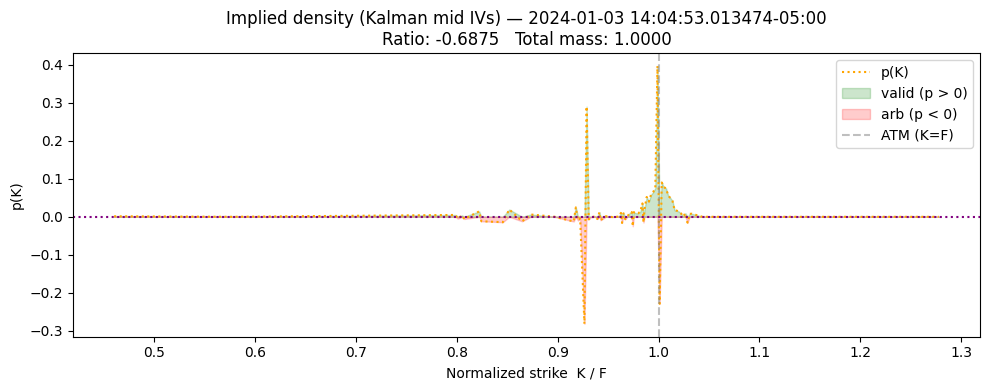

-0.6874612868166867 0.9999999999999999


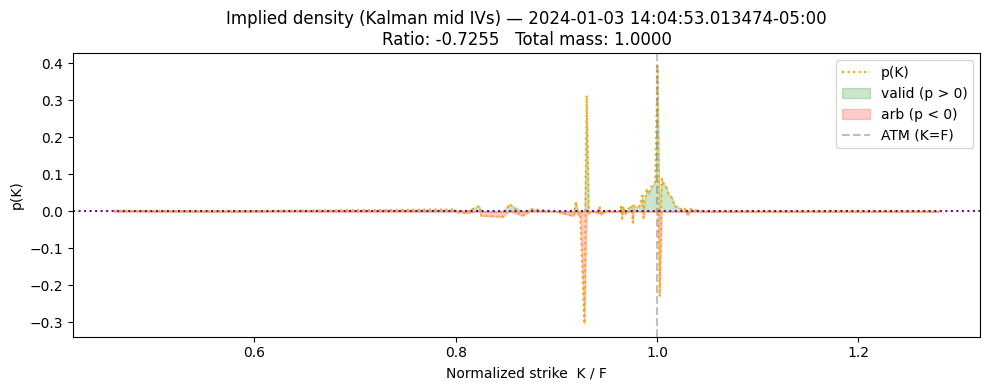

-0.7254795027615826 1.0000000000000002


In [ ]:
has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

for i in [2000000, 2144000]:
    row = df_filtered[i]
    ts = row["ts_ns"][0]
    tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
    spy_mid = df_spy.filter(pl.col("ts_ns") <= ts)["price"][-1]

    valid_strikes, valid_ivs = [], []
    for k in otm_strikes:
        K_int = int(k)
        has_C = k in has_C_set
        has_P = k in has_P_set

        if has_C and has_P:
            bid_C, ask_C = row[f"bid_iv_{K_int}_C"][0], row[f"ask_iv_{K_int}_C"][0]
            bid_P, ask_P = row[f"bid_iv_{K_int}_P"][0], row[f"ask_iv_{K_int}_P"][0]
            i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
            iv = (
                (i_bid + i_ask) / 2
                if i_bid <= i_ask
                else (
                    row[f"kalman_iv_{K_int}_C"][0]
                    if k > spy_mid
                    else row[f"kalman_iv_{K_int}_P"][0]
                )
            )
        elif has_C:
            iv = row[f"kalman_iv_{K_int}_C"][0]
        elif has_P:
            iv = row[f"kalman_iv_{K_int}_P"][0]
        else:
            continue

        valid_strikes.append(k)
        valid_ivs.append(iv)

    F = spy_mid  # forward ≈ spot (r=0)
    tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

    # Filter strikes with a valid Kalman mid IV
    valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
    strikes = np.array([v[0] for v in valid])
    ivs = np.array([v[1] for v in valid])

    # Normalize to pure space: kappa = K/F, C_pure = C_BS / F
    pure_strikes = strikes / F
    pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

    # Extend strike grid with boundary conditions
    strikesx = np.zeros(len(pure_strikes) + 2)
    strikesx[1:-1] = pure_strikes
    strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
    strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

    midx = np.zeros_like(strikesx)
    midx[1:-1] = pure_mids
    midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
    midx[-1] = 0.0  # deep OTM call → 0

    # Breeden-Litzenberger: d²C/dK² = risk-neutral density
    dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
    p = np.diff(dCdK, append=0.0)

    ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
    total = np.sum(p)  # should be ≈ 1

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.set_title(
        f"Implied density (Kalman mid IVs) — {snapshot_ts}\nRatio: {ratio:.4f}   Total mass: {total:.4f}"
    )
    ax.set_xlabel("Normalized strike  K / F")
    ax.set_ylabel("p(K)")
    ax.plot(strikesx, p, ":", color="orange", label="p(K)")
    ax.fill_between(
        strikesx, 0, np.clip(p, 0, None), color="green", alpha=0.2, label="valid (p > 0)"
    )
    ax.fill_between(strikesx, np.clip(p, None, 0), 0, color="red", alpha=0.2, label="arb (p < 0)")
    ax.axhline(0, color="purple", linestyle=":")
    ax.axvline(1.0, color="gray", linestyle="--", alpha=0.5, label="ATM (K=F)")
    ax.legend()
    plt.tight_layout()
    plt.show()

    print(ratio, total)

In [ ]:
strikesx

array([0.46070172, 0.57587715, 0.79982937, 0.80196225, 0.806228  ,
       0.80836088, 0.82329103, 0.82542391, 0.84675269, 0.85315133,
       0.8659486 , 0.87448011, 0.89794177, 0.91713768, 0.91927056,
       0.92140343, 0.92353631, 0.92780207, 0.92993495, 0.93206783,
       0.9342007 , 0.93846646, 0.94059934, 0.94273222, 0.94379866,
       0.94913085, 0.95552949, 0.95766237, 0.95979524, 0.96192812,
       0.964061  , 0.96512744, 0.96619388, 0.96832676, 0.97045964,
       0.97259251, 0.97472539, 0.97579183, 0.97685827, 0.97899115,
       0.98112403, 0.98325691, 0.98538978, 0.98645622, 0.98752266,
       0.98965554, 0.99178842, 0.9939213 , 0.99605418, 0.99818705,
       1.00031993, 1.00245281, 1.00458569, 1.00671857, 1.00885145,
       1.01098432, 1.0131172 , 1.01525008, 1.01738296, 1.01951584,
       1.02164871, 1.02378159, 1.02591447, 1.02804735, 1.03018023,
       1.03231311, 1.03444598, 1.04511038, 1.05150901, 1.06643916,
       1.27972699])

In [ ]:
ratio, total

(np.float64(-0.7254795027615826), np.float64(1.0000000000000002))

In [ ]:
# import re


# def extract_prices_from_row(row):
#     pattern = re.compile(r"^(bid_price|ask_price|observed_price)_(\d+)_(C|P)$")

#     calls, puts = {}, {}
#     for col in row.columns:
#         m = pattern.match(col)
#         if not m:
#             continue
#         price_type, strike, cp = m.group(1), int(m.group(2)), m.group(3)
#         d = calls if cp == "C" else puts
#         d.setdefault(strike, {})[price_type] = row[col][0]

#     strikes_C = sorted(calls)
#     strikes_P = sorted(puts)

#     bid_C = [calls[k].get("bid_price") for k in strikes_C]
#     ask_C = [calls[k].get("ask_price") for k in strikes_C]
#     observed_C = [calls[k].get("observed_price") for k in strikes_C]

#     bid_P = [puts[k].get("bid_price") for k in strikes_P]
#     ask_P = [puts[k].get("ask_price") for k in strikes_P]
#     observed_P = [puts[k].get("observed_price") for k in strikes_P]

#     return strikes_C, bid_C, ask_C, observed_C, strikes_P, bid_P, ask_P, observed_P
